In [ ]:
!pip install -q kaggle

from google.colab import files
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [ ]:
!kaggle datasets download -d abhishek14398/salary-dataset-simple-linear-regression --unzip

Dataset URL: https://www.kaggle.com/datasets/abhishek14398/salary-dataset-simple-linear-regression
License(s): CC0-1.0
100% 457/457 [00:00<00:00, 1.21MB/s]



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


['.config', 'kaggle_prathameshtikle.json', 'Salary_dataset.csv', 'kaggle.json', 'sample_data']


In [ ]:
df = pd.read_csv('Salary_dataset.csv')

df.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


In [ ]:
df_clean=df.copy()
df_clean.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


In [ ]:
df_clean.dropna(inplace=True)
df_clean.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


In [ ]:
df_clean.duplicated().sum()
df_clean.drop_duplicates(inplace=True)

In [ ]:
df_clean

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0
5,5,3.0,56643.0
6,6,3.1,60151.0
7,7,3.3,54446.0
8,8,3.3,64446.0
9,9,3.8,57190.0


In [ ]:
display(df_clean.head())

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


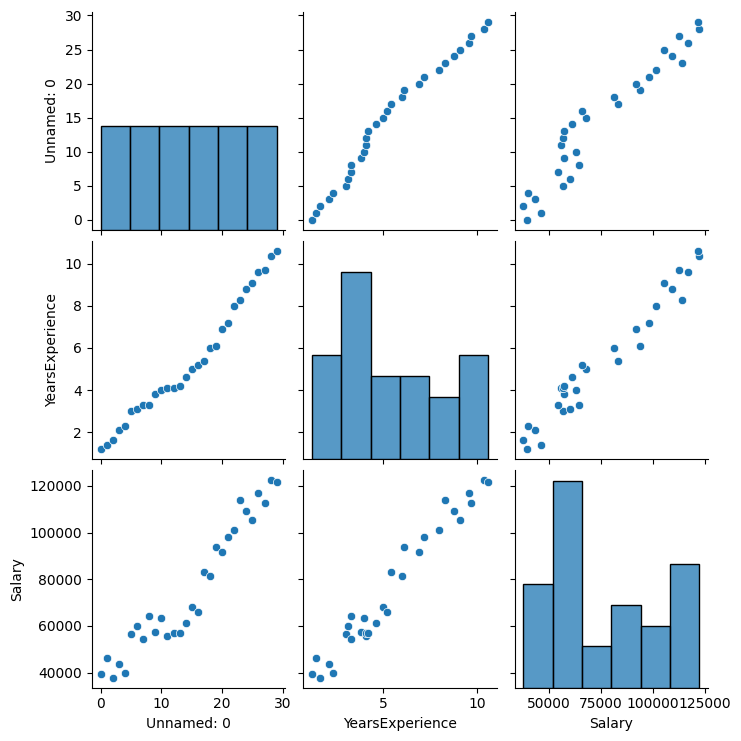

In [ ]:
sns.pairplot(df)

In [ ]:
df_clean['YearsExperience_Squared'] = df_clean['YearsExperience'] ** 2
df_clean.head()

,Unnamed: 0,YearsExperience,Salary,YearsExperience_Squared
0,0,1.2,39344.0,1.44
1,1,1.4,46206.0,1.96
2,2,1.6,37732.0,2.56
3,3,2.1,43526.0,4.41
4,4,2.3,39892.0,5.29


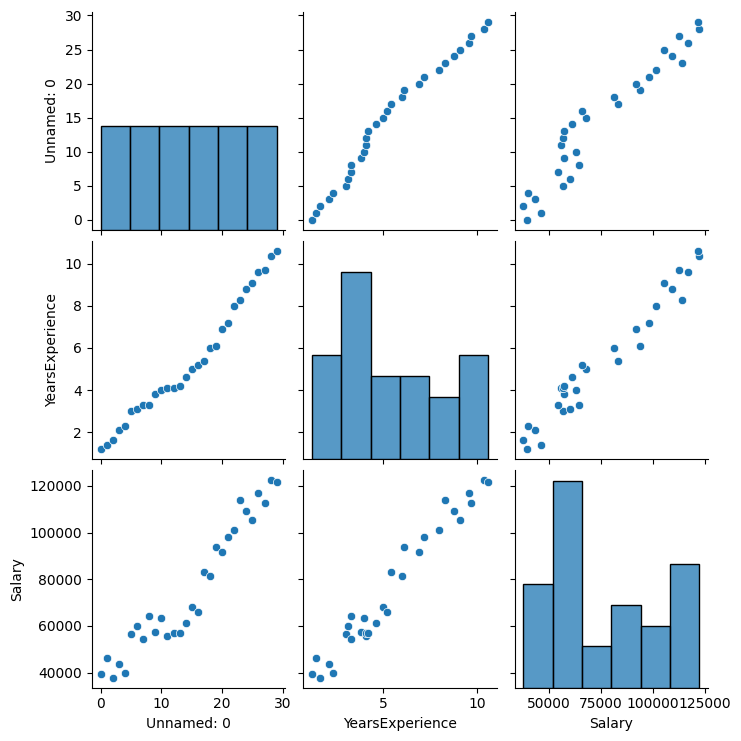

In [ ]:
sns.pairplot(df)

In [ ]:
from sklearn.model_selection import train_test_split
x = df_clean[['YearsExperience', 'YearsExperience_Squared']]
y = df_clean['Salary']
x_train, x_test, y_train, y_test = train_test_split(x, y,test_size=0.2)

In [ ]:
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((24, 2), (6, 2), (24,), (6,))

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(x_test)
y_pred

array([ 47139.59188213,  56281.19918284,  56281.19918284, 107662.90633085,
        73820.23339369,  92523.00019427])

In [ ]:
from sklearn.metrics import *

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print('MAE:', mae)
print('MSE:', mse)
print('RMSE:', rmse)
print('R2:', r2)

MAE: 5426.319791784325
MSE: 36575157.336418755
RMSE: 6047.7398535666825
R2: 0.9377126602720828


In [ ]:
years = float(input("Enter years of experience: "))

# Create input with both features
new_employee = pd.DataFrame({
    'YearsExperience': [years],
    'YearsExperience_Squared': [years ** 2]
})

# Predict salary
predicted_salary = model.predict(new_employee)

print(f"\nYears of Experience: {years}")
print(f"Predicted Salary: {predicted_salary[0]:,.2f}")

Enter years of experience: 2.4

Years of Experience: 2.4
Predicted Salary: 48,050.98


In [ ]:
data = pd.DataFrame({
    'YearsExperience': [1.1, 1.3, 1.5, 2.0, 2.2, 2.9, 3.0, 3.2, 3.2, 3.7,
                        3.9, 4.0, 4.0, 4.1, 4.5, 4.9, 5.1, 5.3, 5.9, 6.0,
                        6.8, 7.1, 7.9, 8.2, 8.7, 9.0, 9.5, 9.6, 10.3, 10.5],
    'Age': [25, 26, 24, 28, 27, 30, 32, 31, 33, 34,
            35, 36, 36, 37, 38, 40, 41, 42, 44, 45,
            46, 47, 48, 49, 50, 51, 52, 53, 54, 55],
    'EducationLevel': [1, 2, 1, 2, 2, 3, 3, 2, 2, 3,
                       3, 3, 2, 2, 3, 3, 3, 3, 3, 3,
                       3, 3, 3, 3, 3, 3, 3, 3, 3, 3],
    'Salary': [39343, 46205, 37731, 43525, 39891, 56642, 60150, 54445, 64445, 57189,
               63218, 55794, 56957, 57081, 61111, 67938, 66029, 83088, 81363, 93940,
               91738, 98273, 101302, 113812, 109431, 105582, 116969, 112635, 122391, 121872]
})

In [ ]:
a = data[['YearsExperience', 'Age', 'EducationLevel']]
b = data['Salary']

In [ ]:
a_train, a_test, b_train, b_test = train_test_split(a, b, test_size=0.2)

In [ ]:
model = LinearRegression()
model.fit(a_train, b_train)

LinearRegression()

In [ ]:
b_pred = model.predict(a_test)
b_pred

array([ 61359.52049943, 107461.2232663 ,  52519.64938706,  83440.3236916 ,
        65013.29079667,  37112.27105436])

In [ ]:
import pandas as pd

experience = float(input("Enter years of experience: "))
age = int(input("Enter age: "))
education = int(input("Enter education level (1, 2, or 3): "))

new_employee = pd.DataFrame({
    'YearsExperience': [experience],
    'Age': [age],
    'EducationLevel': [education]
})

predicted_salary = model.predict(new_employee)

print(f"Years of Experience: {experience}")
print(f"Age: {age}")
print(f"Education Level: {education}")
print(f"Predicted Salary: {predicted_salary[0]:,.2f}")

Enter years of experience: 3
Enter age: 22
Enter education level (1, 2, or 3): 3
Years of Experience: 3.0
Age: 22
Education Level: 3
Predicted Salary: 42,076.88
